In [1]:
import pandas as pd

# Load the dataset
df = pd.read_csv('data_core.csv')  # use the exact filename you uploaded

# Basic shape check
print("Shape (rows, columns):", df.shape)
df.head()

Shape (rows, columns): (8000, 9)


,Temparature,Humidity,Moisture,Soil Type,Crop Type,Nitrogen,Potassium,Phosphorous,Fertilizer Name
0,26.0,52.0,38.0,Sandy,Maize,37,0,0,Urea
1,29.0,52.0,45.0,Loamy,Sugarcane,12,0,36,DAP
2,34.0,65.0,62.0,Black,Cotton,7,9,30,14-35-14
3,32.0,62.0,34.0,Red,Tobacco,22,0,20,28-28
4,28.0,54.0,46.0,Clayey,Paddy,35,0,0,Urea


In [3]:
# 1. Check for missing values in each column
print("--- Missing Values ---")
print(df.isnull().sum())
print()

# 2. Check for duplicate rows
print("--- Duplicate Rows ---")
print("Total duplicates:", df.duplicated().sum())
print()

# 3. Check column data types
print("--- Data Types ---")
print(df.dtypes)
print()

# 4. Check unique categories
print("--- Categorical Values ---")
print("Soil Types:", df['Soil Type'].unique())
print("Crop Types:", df['Crop Type'].unique())
print("Fertilizer Classes (Target):", df['Fertilizer Name'].unique())

--- Missing Values ---
Temparature        0
Humidity           0
Moisture           0
Soil Type          0
Crop Type          0
Nitrogen           0
Potassium          0
Phosphorous        0
Fertilizer Name    0
dtype: int64

--- Duplicate Rows ---
Total duplicates: 0

--- Data Types ---
Temparature        float64
Humidity           float64
Moisture           float64
Soil Type           object
Crop Type           object
Nitrogen             int64
Potassium            int64
Phosphorous          int64
Fertilizer Name     object
dtype: object

--- Categorical Values ---
Soil Types: ['Sandy' 'Loamy' 'Black' 'Red' 'Clayey']
Crop Types: ['Maize' 'Sugarcane' 'Cotton' 'Tobacco' 'Paddy' 'Barley' 'Wheat' 'Millets'
 'Oil seeds' 'Pulses' 'Ground Nuts']
Fertilizer Classes (Target): ['Urea' 'DAP' '14-35-14' '28-28' '17-17-17' '20-20' '10-26-26']


In [4]:
from sklearn.model_selection import train_test_split

# 1. Separate features (X) from the target label (y)
X = df.drop(columns=['Fertilizer Name'])
y = df['Fertilizer Name']

# 2. Perform stratified split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# 3. Display the shapes
print(f'Original dataset shape: X={X.shape}, y={y.shape}')
print(
    f'Training set shape:     X_train={X_train.shape}, y_train={y_train.shape}'
)
print(f'Testing set shape:      X_test={X_test.shape}, y_test={y_test.shape}')

Original dataset shape: X=(8000, 8), y=(8000,)
Training set shape:     X_train=(6400, 8), y_train=(6400,)
Testing set shape:      X_test=(1600, 8), y_test=(1600,)


In [5]:
# Compare percentage distribution of each class across full, train, and test sets
dist_comparison = pd.DataFrame(
    {
        "Full Dataset (%)": (y.value_counts(normalize=True) * 100).round(2),
        "Training Set (%)": (
            y_train.value_counts(normalize=True) * 100
        ).round(2),
        "Test Set (%)": (y_test.value_counts(normalize=True) * 100).round(2),
    }
)

dist_comparison

,Full Dataset (%),Training Set (%),Test Set (%)
Fertilizer Name,,,
14-35-14,14.85,14.84,14.88
Urea,14.62,14.62,14.62
DAP,14.59,14.59,14.56
10-26-26,14.10,14.09,14.12
17-17-17,14.05,14.05,14.06
28-28,14.00,14.00,14.00
20-20,13.79,13.80,13.75


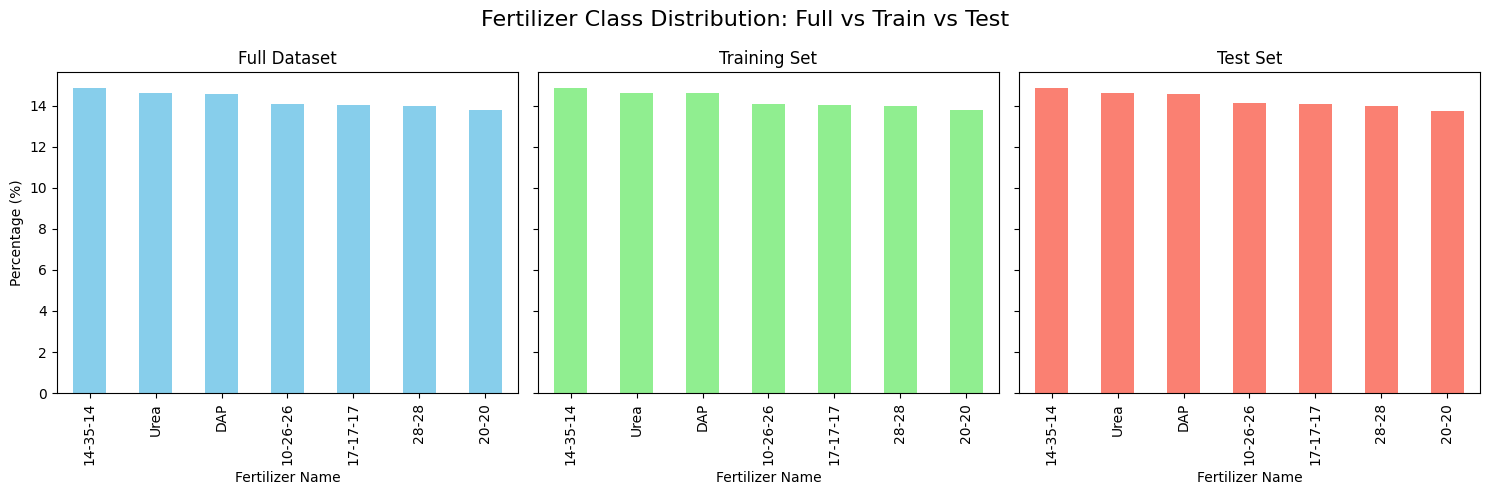

In [6]:
import matplotlib.pyplot as plt

# Set up the figure with 3 subplots side-by-side
fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
fig.suptitle('Fertilizer Class Distribution: Full vs Train vs Test', fontsize=16)

# Plot 1: Full Dataset
(y.value_counts(normalize=True) * 100).plot(kind='bar', ax=axes[0], color='skyblue')
axes[0].set_title('Full Dataset')
axes[0].set_ylabel('Percentage (%)')

# Plot 2: Training Set
(y_train.value_counts(normalize=True) * 100).plot(kind='bar', ax=axes[1], color='lightgreen')
axes[1].set_title('Training Set')

# Plot 3: Test Set
(y_test.value_counts(normalize=True) * 100).plot(kind='bar', ax=axes[2], color='salmon')
axes[2].set_title('Test Set')

# Adjust layout and show
plt.tight_layout()
plt.show()

Why Stratification is Important:
Using a stratified split ensures that the proportion of each of the 7 fertilizer classes remains exactly the same in both the training and test sets as it is in the full dataset. If we used a random split, an uneven distribution could occur where a specific class might be overrepresented in the training set and underrepresented in the test set, which would ruin our model's evaluation.

Preventing Data Leakage:
It is critical that preprocessing transformations (such as scaling numerical features) are fitted only using the training data. If we fit a scaler on the entire dataset before the train-test split, the model gets a 'sneak peek' at the test data's overall distribution. This causes data leakage and results in falsely high accuracy.